In [2]:
%pip install mysql-connector-python

  Using cached mysql_connector_python-26.10.0-cp313-cp313-win_amd64.whl.metadata (11 kB)
Using cached mysql_connector_python-26.10.0-cp313-cp313-win_amd64.whl (17.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
from getpass import getpass

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password=getpass("Enter MySQL password: "),
    database="automobile_db"
)

print("Successfully connected to MySQL!")

Successfully connected to MySQL!


In [13]:
query = "SELECT * FROM automobile_raw"

df = pd.read_sql(query, connection)

print("Total records:", len(df))
print(df.head())

Total records: 205
  symboling normalized_losses         make fuel_type aspiration num_of_doors  \
0         3                 ?  alfa-romero       gas        std          two   
1         3                 ?  alfa-romero       gas        std          two   
2         1                 ?  alfa-romero       gas        std          two   
3         2               164         audi       gas        std         four   
4         2               164         audi       gas        std         four   

    body_style drive_wheels engine_location wheel_base  ... engine_size  \
0  convertible          rwd           front      88.60  ...         130   
1  convertible          rwd           front      88.60  ...         130   
2    hatchback          rwd           front      94.50  ...         152   
3        sedan          fwd           front      99.80  ...         109   
4        sedan          4wd           front      99.40  ...         136   

  fuel_system  bore stroke compression_ratio hors

C:\Users\vijay\AppData\Local\Temp\ipykernel_21356\1816764157.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


In [5]:
# Replace '?' with missing values
df.replace('?', np.nan, inplace=True)

# Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
symboling             0
normalized_losses    41
make                  0
fuel_type             0
aspiration            0
num_of_doors          2
body_style            0
drive_wheels          0
engine_location       0
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_type           0
num_of_cylinders      0
engine_size           0
fuel_system           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 4
dtype: int64


In [6]:
# Convert important columns into numeric values
numeric_columns = [
    'price',
    'horsepower',
    'engine_size',
    'city_mpg',
    'highway_mpg',
    'curb_weight'
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

print("Numeric conversion completed!")
print(df[numeric_columns].dtypes)

Numeric conversion completed!
price          float64
horsepower     float64
engine_size      int64
city_mpg         int64
highway_mpg      int64
curb_weight      int64
dtype: object


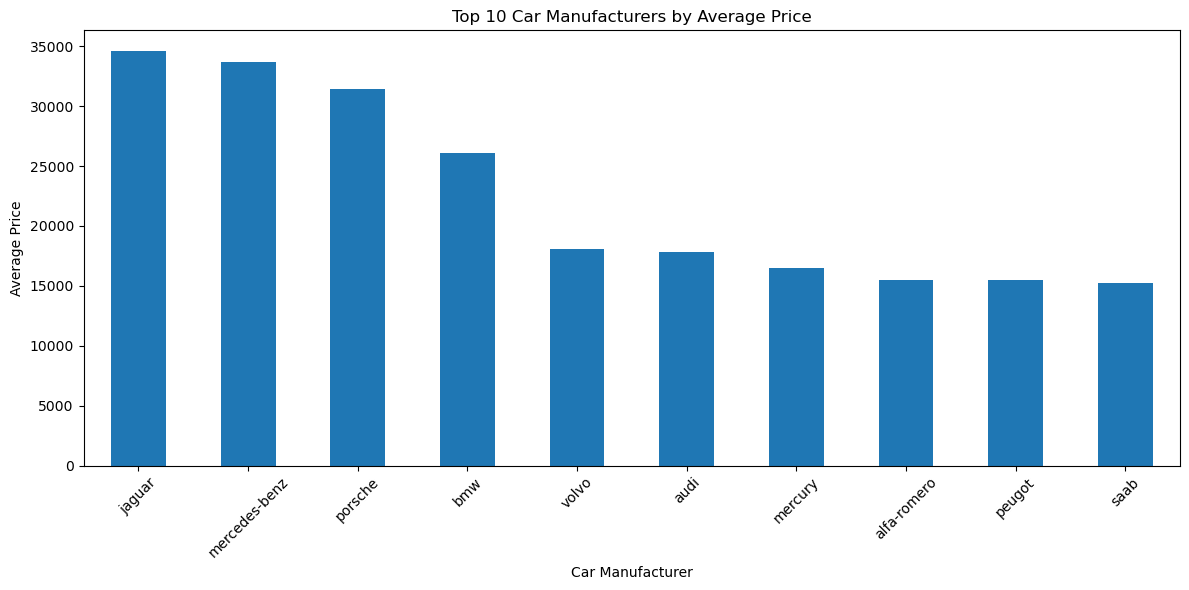

In [7]:
# Calculate average price for each car manufacturer
average_price = df.groupby('make')['price'].mean().sort_values(ascending=False)

# Select the top 10 manufacturers
top_10 = average_price.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))
top_10.plot(kind='bar')

plt.title('Top 10 Car Manufacturers by Average Price')
plt.xlabel('Car Manufacturer')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

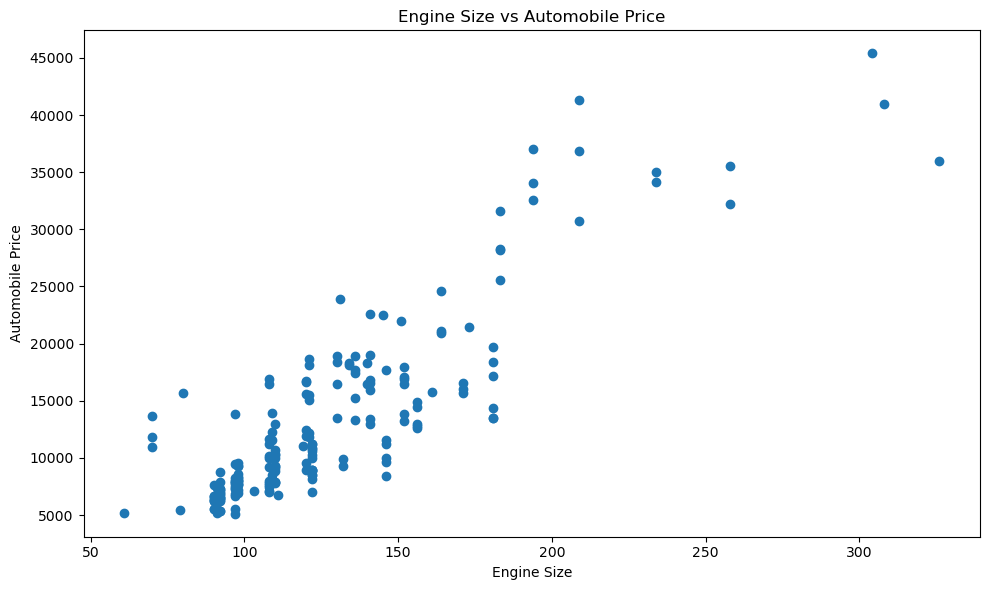

In [8]:
# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(df['engine_size'], df['price'])

plt.title('Engine Size vs Automobile Price')
plt.xlabel('Engine Size')
plt.ylabel('Automobile Price')

plt.tight_layout()
plt.show()

In [9]:
# Generate statistical summary
print("Automobile Dataset Summary")
print("--------------------------")

print("Total automobiles:", len(df))
print("Number of manufacturers:", df['make'].nunique())

print("\nAverage automobile price:", round(df['price'].mean(), 2))
print("Highest automobile price:", df['price'].max())
print("Lowest automobile price:", df['price'].min())

print("\nAverage engine size:", round(df['engine_size'].mean(), 2))
print("Average city mileage:", round(df['city_mpg'].mean(), 2))
print("Average highway mileage:", round(df['highway_mpg'].mean(), 2))

Automobile Dataset Summary
--------------------------
Total automobiles: 205
Number of manufacturers: 22

Average automobile price: 13207.13
Highest automobile price: 45400.0
Lowest automobile price: 5118.0

Average engine size: 126.91
Average city mileage: 25.22
Average highway mileage: 30.75


In [10]:
# Save cleaned dataset as CSV
df.to_csv('cleaned_automobile_data.csv', index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [11]:

top_make = df.groupby('make')['price'].mean().idxmax()
top_price = df.groupby('make')['price'].mean().max()

correlation = df[['engine_size', 'price']].corr().iloc[0, 1]

print("KEY FINDINGS")
print("============")
print("1. The dataset contains", len(df), "automobile records.")
print("2. It includes", df['make'].nunique(), "different manufacturers.")
print("3. The manufacturer with the highest average car price is:",
      top_make)
print("4. Its average car price is:", round(top_price, 2))
print("5. Correlation between engine size and price:",
      round(correlation, 2))

if correlation > 0:
    print("6. Engine size and price have a positive relationship.")
elif correlation < 0:
    print("6. Engine size and price have a negative relationship.")
else:
    print("6. There is no linear relationship between engine size and price.")

KEY FINDINGS
1. The dataset contains 205 automobile records.
2. It includes 22 different manufacturers.
3. The manufacturer with the highest average car price is: jaguar
4. Its average car price is: 34600.0
5. Correlation between engine size and price: 0.87
6. Engine size and price have a positive relationship.


## Key Findings and Observations

1. The dataset contains 205 automobile records.
2. It includes 22 different automobile manufacturers.
3. Jaguar has the highest average automobile price, at 34,600.
4. The correlation between engine size and automobile price is 0.87, indicating a strong positive relationship.
5. The analysis suggests that automobiles with larger engine sizes generally have higher prices.

## Conclusion

This project demonstrates how Python can connect to a MySQL database, retrieve automobile data, clean and process the data using Pandas and NumPy, and visualize insights using Matplotlib.

The analysis indicates that engine size is strongly positively associated with automobile price. These insights can help us understand automobile pricing patterns.